#### Import Core Dependencies

In [13]:
import torch
import pandas as pd
import numpy as np
from datasets import load_dataset
from transformers import AutoTokenizer
from typing import Any
from pathlib import Path
from collections import Counter
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.nn.functional as F
import math
from tqdm.auto import tqdm
import ast
import statistics as stats

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# verify paths are operational
print(Path("../data/raw/").exists())
print(Path("../checkpoints").exists())

True
True


In [3]:
print("PyTorch:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

PyTorch: 2.14.0+cpu
CUDA Available: False


### Load and Inspect Data

In [4]:
# create path variables for ease of navigation
DATA_PATH = Path("../data/raw/")

lines_path = DATA_PATH / "movie_lines.txt"
conversation_path = DATA_PATH / "movie_conversations.txt"

In [ ]:
# read first few lines
with open(lines_path, "r", encoding="iso-8859-1") as f:
    for _ in range(5):
        print(f.readline().strip())

L1045 +++$+++ u0 +++$+++ m0 +++$+++ BIANCA +++$+++ They do not!
L1044 +++$+++ u2 +++$+++ m0 +++$+++ CAMERON +++$+++ They do to!
L985 +++$+++ u0 +++$+++ m0 +++$+++ BIANCA +++$+++ I hope so.
L984 +++$+++ u2 +++$+++ m0 +++$+++ CAMERON +++$+++ She okay?
L925 +++$+++ u0 +++$+++ m0 +++$+++ BIANCA +++$+++ Let's go.


In [6]:
with open(conversation_path, "r", encoding="iso-8859-1") as f:
    for _ in range(5):
        print(f.readline().strip())

u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L194', 'L195', 'L196', 'L197']
u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L198', 'L199']
u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L200', 'L201', 'L202', 'L203']
u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L204', 'L205', 'L206']
u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L207', 'L208']


In [7]:
with open(lines_path, "r", encoding="iso-8859-1") as f:
    num_lines = sum(1 for _ in f)

print(f"Movie lines: {num_lines:,}")

Movie lines: 304,713


In [ ]:
with open(conversation_path, "r", encoding="iso-8859-1") as f:
    num_conversations = sum(1 for _ in f)

print(f"Conversations: {num_conversations:,}")
# the documentation mentioned over 220K conversational exchanges which I presume would not whole conversations which is counted below

Conversations: 83,097


In [11]:
with open(
    lines_path,
    encoding="iso-8859-1"
) as f:

    sample_line = f.readline()

print(sample_line)
print(sample_line.split(" +++$+++ "))

L1045 +++$+++ u0 +++$+++ m0 +++$+++ BIANCA +++$+++ They do not!

['L1045', 'u0', 'm0', 'BIANCA', 'They do not!\n']


In [12]:
with open(
    conversation_path,
    encoding="iso-8859-1"
) as f:

    sample_conv = f.readline()

print(sample_conv)
print(sample_conv.split(" +++$+++ "))

u0 +++$+++ u2 +++$+++ m0 +++$+++ ['L194', 'L195', 'L196', 'L197']

['u0', 'u2', 'm0', "['L194', 'L195', 'L196', 'L197']\n"]


In [14]:
conversation_lengths = []

with open(conversation_path, "r", encoding="iso-8859-1") as f:

    for line in f:

        parts = line.strip().split(" +++$+++ ")

        line_ids = ast.literal_eval(parts[-1])

        conversation_lengths.append(
            len(line_ids)
        )

print(f"Min Length   : {min(conversation_lengths)}")
print(f"Mean Length  : {stats.mean(conversation_lengths):.2f}")
print(f"Median Length: {stats.median(conversation_lengths)}")
print(f"Max Length   : {max(conversation_lengths)}")

Min Length   : 2
Mean Length  : 3.67
Median Length: 3
Max Length   : 89


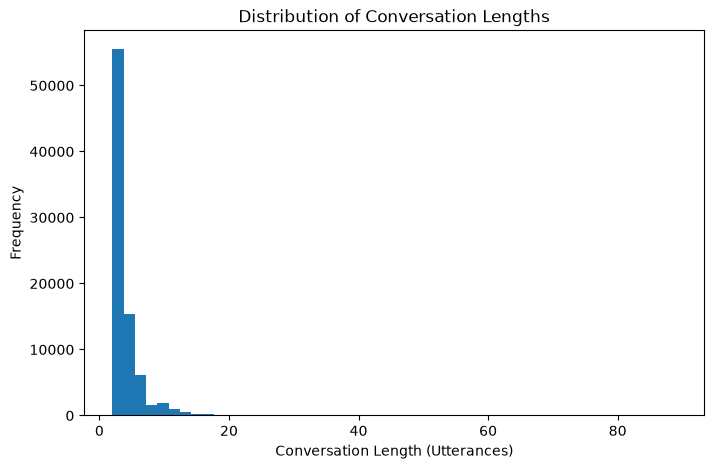

In [15]:
plt.figure(figsize=(8,5))

plt.hist(
    conversation_lengths,
    bins=50
)

plt.xlabel("Conversation Length (Utterances)")
plt.ylabel("Frequency")
plt.title("Distribution of Conversation Lengths")

plt.show()